In [24]:
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone


In [25]:
data=pd.read_csv('heart.csv')

In [26]:
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [27]:
data.shape

(303, 14)

In [28]:
data.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [29]:
data.duplicated().sum()

np.int64(1)

In [30]:
data.shape

(303, 14)

In [31]:
data.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [32]:
data.groupby("target")[["age", "thalach", "oldpeak", "ca", "exang"]].mean().round(2)

,age,thalach,oldpeak,ca,exang
target,,,,,
0,56.6,139.10,1.59,1.17,0.55
1,52.5,158.47,0.58,0.36,0.14


In [33]:
data["target"] = 1 - data["target"]

print(data["target"].value_counts())
print(data.groupby("target")[["thalach", "oldpeak", "ca", "exang"]].mean().round(2))

target
0    165
1    138
Name: count, dtype: int64
        thalach  oldpeak    ca  exang
target                               
0        158.47     0.58  0.36   0.14
1        139.10     1.59  1.17   0.55


In [34]:
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]

In [35]:
# creating pipelines

numpipeline= Pipeline(steps=[('impute',SimpleImputer(strategy='median',))
                             ,('scale',StandardScaler())])
catepipeline=Pipeline(steps=[('impute',SimpleImputer(strategy='most_frequent')),
                             ('encode',OneHotEncoder(handle_unknown='ignore'))])

In [36]:
# combining pipelines 

features= ColumnTransformer(transformers=
                            [('numtransform',numpipeline,num_cols),
                            ('categorical transformation',catepipeline,cat_cols)])

In [37]:
X = data.drop(columns="target")   
y = data["target"]                

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [38]:
lr = Pipeline(steps=[
    ('preprocessor', features),
    ('classifier', LogisticRegression(max_iter=1000))
])

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

In [39]:
y_pred_lr

array([0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1])

In [40]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [41]:
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier          # run %pip install xgboost once if missing
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC(probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42),
}

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", clone(features)), ("model", model)])
    pipe.fit(X_train, y_train)

    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]

    print("=====", name, "=====")
    print(classification_report(y_test, pred, target_names=["No disease", "Disease"]))

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

pd.DataFrame(rows).set_index("Model").round(3).sort_values("Recall", ascending=False)

===== Logistic Regression =====
              precision    recall  f1-score   support

  No disease       0.83      0.91      0.87        33
     Disease       0.88      0.79      0.83        28

    accuracy                           0.85        61
   macro avg       0.86      0.85      0.85        61
weighted avg       0.85      0.85      0.85        61

===== SVM =====
              precision    recall  f1-score   support

  No disease       0.81      0.91      0.86        33
     Disease       0.88      0.75      0.81        28

    accuracy                           0.84        61
   macro avg       0.84      0.83      0.83        61
weighted avg       0.84      0.84      0.83        61

===== Random Forest =====
              precision    recall  f1-score   support

  No disease       0.76      0.88      0.82        33
     Disease       0.83      0.68      0.75        28

    accuracy                           0.79        61
   macro avg       0.79      0.78      0.78        61


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.852,0.880,0.786,0.830,0.907
SVM,0.836,0.875,0.750,0.808,0.899
XGBoost,0.770,0.769,0.714,0.741,0.878
Random Forest,0.787,0.826,0.679,0.745,0.878


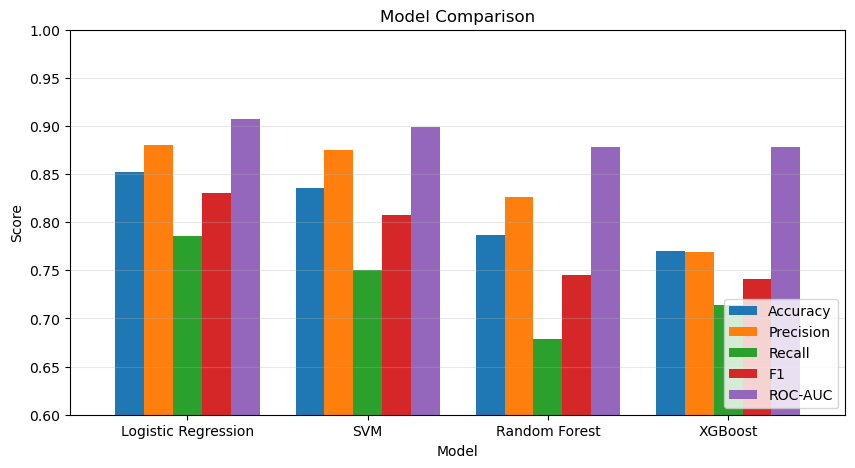

In [42]:
import matplotlib.pyplot as plt

comparison = pd.DataFrame(rows).set_index("Model")

comparison.plot(kind="bar", figsize=(10, 5), width=0.8)
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0.6, 1.0)          # starts at 0.6 so small gaps are visible
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [43]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", clone(features)), ("model", clone(model))])
    auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    rec = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="recall")
    cv_rows.append({"Model": name,
                    "ROC-AUC": auc.mean(), "AUC std": auc.std(),
                    "Recall": rec.mean(), "Recall std": rec.std()})

cv_table = pd.DataFrame(cv_rows).set_index("Model").round(3)
cv_table.sort_values("ROC-AUC", ascending=False)

,ROC-AUC,AUC std,Recall,Recall std
Model,,,,
Random Forest,0.902,0.036,0.809,0.053
SVM,0.900,0.039,0.800,0.098
Logistic Regression,0.889,0.041,0.764,0.097
XGBoost,0.886,0.028,0.782,0.053


In [44]:
fitted = {}
for name, model in models.items():
    p = Pipeline([("prep", clone(features)), ("model", clone(model))])
    p.fit(X_train, y_train)
    fitted[name] = p

print(list(fitted.keys()))

['Logistic Regression', 'SVM', 'Random Forest', 'XGBoost']


In [48]:
import pickle
from sklearn.metrics import classification_report

best_model = fitted["SVM"]

pred = best_model.predict(X_test)
print(classification_report(y_test, pred, target_names=["No disease", "Disease"]))

with open("heart_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

print("Saved SVM with corrected labels")

              precision    recall  f1-score   support

  No disease       0.81      0.91      0.86        33
     Disease       0.88      0.75      0.81        28

    accuracy                           0.84        61
   macro avg       0.84      0.83      0.83        61
weighted avg       0.84      0.84      0.83        61

Saved SVM with corrected labels


# Model Testing

In [55]:
import pickle

with open("heart_model.pkl", "rb") as f:
    model = pickle.load(f)

sample = X_test.head(10)

result = sample[["age", "sex", "chol", "thalach"]].copy()
result["Actual"] = y_test.head(10).values
result["Predicted"] = model.predict(sample)
result["Disease_prob"] = model.predict_proba(sample)[:, 1].round(2)
result["Correct"] = result["Actual"] == result["Predicted"]

result

,age,sex,chol,thalach,Actual,Predicted,Disease_prob,Correct
121,59,1,271,182,0,0,0.11,True
63,41,1,203,132,0,0,0.45,True
162,41,1,157,182,0,0,0.08,True
48,53,0,216,115,0,0,0.17,True
155,58,0,197,131,0,0,0.12,True
150,66,1,228,138,0,0,0.49,True
102,63,0,195,179,0,0,0.12,True
37,54,1,232,165,0,0,0.38,True
239,35,1,282,156,1,1,0.70,True
50,51,0,256,149,0,0,0.02,True
